# Exercise 5
**Veikka Immonen**

In [1]:
import numpy as np
import scipy as sci
import scipy.sparse as sp
import matplotlib.pyplot as plt
from sksparse.cholmod import cholesky
from collections.abc import Iterable
from itertools import product
from tqdm import tqdm

import scienceplots
plt.style.use(['science'])

## Matérn sampler via SPDE approximation

In [2]:
def log_tau(d, nu, kappa, sigma):
    return (
        0.5 * (sci.special.gammaln(nu) - sci.special.gammaln(nu + d/2))
        - nu * np.log(kappa)
        - (d / 4) * np.log(4 * np.pi)
        - np.log(sigma)
    )


def build_laplacian_1d(n, step_inv, periodic=False):
    c = step_inv**2
    L = sp.diags(
        diagonals=[c , -2*c, c],
        offsets=[-1, 0, 1],
        shape=(n, n), format="lil"
    )
    if periodic:
        L[0, -1] = c
        L[-1, 0] = c
    else:
        # Homogeneous Neumann boundaries.
        L[0, 0] = -c
        L[-1, -1] = -c
    return L.tocsc()


def build_laplacian(shape, step_inv, periodic=None):

    assert isinstance(shape, Iterable)
    assert isinstance(step_inv, Iterable)
    assert len(shape) == len(step_inv)
    if periodic is None:
        periodic = (False,) * len(shape)
    assert isinstance(periodic, Iterable)
    assert len(periodic) == len(shape)

    out = None
    for i, (n, h_inv, p) in enumerate(zip(shape, step_inv, periodic)):
        L = build_laplacian_1d(n, h_inv, p)
        left = int(np.prod(shape[:i]))
        right = int(np.prod(shape[i+1:]))
        term = sp.kron(
            sp.kron(sp.eye(left, format="csc"), L),
            sp.eye(right, format="csc")
        )
        out = term if out is None else out + term

    return out


class MaternFDMSPDESampler:

    def __init__(self, boundaries, shape, periodic, nu, ell, sigma, pad=1):
        """
        FDM-based sampler for a Matérn Gaussian field using the SPDE formulation.

        Parameters
        ----------
        boundaries : tuple of pair of floats
            Boundaries of the regular grid
        shape : tuple
            Discretization size of each axis
        periodic : tuple
            Tuple of booleans indicating wether the grid is periodic or not
        nu : float
            Matérn smoothness parameter. Must satisfy
            nu + d/2 ∈ {1, 2, 3, ...}.
        ell : float
            Matérn length scale.
        sigma : float
            Marginal standard deviation.
        pas : int
            Size of extension beyond boundary, if axis is non-periodic

        Notes
        -----
        The created matrices are shared by cloned samplers and are therefore
        treated as read-only. Modifying either matrix after initialization may
        invalidate cached quantities, its factorization, and log(det(K)).
        """

        self.d = len(boundaries)
        alpha_float = nu + self.d / 2
        alpha = round(alpha_float)

        self.boundaries = tuple(map(tuple, boundaries))
        self.shape = tuple(shape)
        self.periodic = tuple(map(bool, periodic))
        self.pad = pad
        self.shape_extended = tuple(
            n if p else n + 2 * self.pad
            for n, p in zip(self.shape, self.periodic)
        )
        self.step_inv = np.array([
            (n - 1 if not p else n) / (b - a)
            for (a, b), n, p in zip(self.boundaries, self.shape, self.periodic)
        ])
        self.slices = tuple(
            slice(None) if p else slice(pad, -pad) if pad > 0 else slice(None)
            for p in self.periodic
        )

        self.n = np.prod(self.shape_extended)
        self.vol_sqrt = np.sqrt(np.prod(1.0 / self.step_inv))
        self.nu = nu
        self.ell = ell
        self.sigma = sigma
        self.kappa = np.sqrt(2 * self.nu) / self.ell
        self.alpha = alpha

        self.L = build_laplacian(self.shape_extended, self.step_inv, self.periodic)
        self.A = self.kappa**2 * sp.eye(self.n, format="csc") - self.L
        self.solve_A = sp.linalg.factorized(self.A)
        self.L_A, self.p_A = cholesky(self.A, lower=True)
        self.pinv_A = np.argsort(self.p_A)
        self.logdet_A = 2.0 * np.log(self.L_A.diagonal()).sum()

        self.tau = np.exp(log_tau(self.d, self.nu, self.kappa, self.sigma))


    def __call__(self, n_samples=1, extended=False):
        """
        Samples Matérn field(s).

        Parameters
        ----------
        n_samples : 
            Number of field realization(s).

        Returns
        -------
        ndarray, shape (n,), if n_samples==1, otherwise (n_samples, n)
        """

        z = np.random.randn(self.n, n_samples)
        if self.alpha % 2 == 1:
            z = z[self.p_A, :]
            w = sp.linalg.spsolve_triangular(self.L_A.T, z, lower=False)
            w = w[self.pinv_A, :]
        else:
            w = z

        for _ in range(self.alpha // 2):
            w = self.solve_A(w)

        w = w.T.reshape((n_samples, *self.shape_extended))
        if not extended:
            w = w[(slice(None), *self.slices)]
        if n_samples == 1:
            w = w[0]

        return w / (self.tau * self.vol_sqrt)


    def logpdf(self, x):
        """
        Evaluate the log-density of the Matérn field.

        Parameters
        ----------
        x : ndarray, of shape_extended or (n_samples, *shape_extended)
            Field realization(s).

        Returns
        -------
        float or ndarray
            Log-density for each realization.
        """

        if x.ndim == len(self.shape):
            assert x.shape == self.shape_extended
            x = x.ravel().reshape((1, -1))
            scalar = True
        elif x.ndim == len(self.shape) + 1:
            assert x.shape[1:] == self.shape_extended
            x = x.reshape((x.shape[0], -1))
            scalar = False
        else:
            raise ValueError("x must have shape shape_extended or (n_samples, *shape_extended)")
        x = x.T

        qx = x
        for _ in range(self.alpha):
            qx = self.A @ qx

        quad = self.tau**2 * self.vol_sqrt**2 * np.sum(x * qx, axis=0)

        logdet_Q = (
            2.0 * self.n * (np.log(self.tau) + np.log(self.vol_sqrt))
            + self.alpha * self.logdet_A
        )

        logp = (
            0.5 * logdet_Q - 0.5 * quad
            - 0.5 * self.n * np.log(2.0 * np.pi)
        )

        return logp[0] if scalar else logp



    def clone(self, *, nu=None, ell=None, sigma=None):
        """
        Create a soft copy of the sampler with optionally modified parameters.

        Parameters
        ----------
        nu : float or None, optional
        ell : float or None, optional
        sigma : float or None, optional

        If a parameter is None, the current value from the original class is retained.

        Returns
        -------
        MaternSPDESampler
            A new sampler instance with the requested parameter values.

        Notes
        -----
        This is a soft copy rather than a deep copy. matrices 
        are intentionally shared between the original and cloned samplers.

        If ell is unchanged, the expensive A-dependent state is also shared:
        K, its Cholesky factorization, permutation, solver, and log-determinant.
        If ell changes, these quantities are recomputed for the new A.

        The shared matrices and cached arrays are therefore assumed to be
        read-only after construction.
        """

        new = object.__new__(type(self))

        new.d = self.d
        new.boundaries = self.boundaries
        new.shape = self.shape
        new.periodic = self.periodic
        new.pad = self.pad
        new.shape_extended = self.shape_extended
        new.step_inv = self.step_inv
        new.slices = self.slices

        new.nu = self.nu if nu is None else nu
        new.ell = self.ell if ell is None else ell
        new.sigma = self.sigma if sigma is None else sigma
        new.kappa = np.sqrt(2 * new.nu) / new.ell
        new.tau = np.exp(log_tau(new.d, new.nu, new.kappa, new.sigma))

        new.n = self.n 
        new.vol_sqrt = self.vol_sqrt
        new.L = self.L

        alpha_float = new.nu + new.d / 2
        alpha = round(alpha_float)
        assert np.isclose(alpha_float, alpha) and alpha >= 1, (
            "alpha = nu + d/2 must be an integer >= 1"
        )
        new.alpha = alpha

        if ell is None:
            new.A = self.A
            new.L_A = self.L_A
            new.p_A = self.p_A
            new.pinv_A = self.pinv_A
            new.solve_A = self.solve_A
            new.logdet_A = self.logdet_A
        else:
            new.A = new.kappa**2 * sp.eye(new.n, format="csc") - new.L
            new.solve_A = sp.linalg.factorized(new.A)
            new.L_A, new.p_A = cholesky(new.A, lower=True)
            new.pinv_A = np.argsort(new.p_A)
            new.logdet_A = 2.0 * np.log(new.L_A.diagonal()).sum()
        return new


## Blind convolution

### Problem definition and data

Define the underlying (and unknown) signal $x: [0, 1] \rightarrow \mathbb{R}$ as
$$
x(t) = \begin{cases}
\exp\left(4 - \frac{25}{10t(5 - 10t)}\right), & t\in(0,0.5) \\
1, & t\in[0.7, 0.8] \\
-1, & t\in(0.8, 0.9] \\
0, & \text{otherwise}
\end{cases},
$$
which is also periodic: $x(t + 1) = x(t)$. The inverse problem model is defined as
$$
y(t) = \int K_\theta(t - t'; \theta)x(t') ~\text{d}t'+ \epsilon(t),
$$
where the convolution operator $K$ as
$$
K(t; \theta) = \begin{cases}\frac{1}{2\theta}, & |t| \le \theta \\ 0, & \text{otherwise}\end{cases}
$$
Discrete matrix approximation is
$$
\bm{y} = \bm{K}_\theta \bm{x} + \bm{\epsilon},
$$
* $\dim(\bm{y}) = n$, $\dim(\bm{x}) = n_*$, $n < n_*$
* $\bm{K}_\theta$: convolution operator
* $\bm{\epsilon} \sim \mathcal{N}(0, \sigma^2\bm{I})$

Moreover data generation uses
* $\theta = 0.05$
* $\sigma = 0.1$
* $n = 50$
* $n_* = 500$



/var/folders/r7/lrp1vtg90zx0m34pgg8fr_bs0yg2r7/T/ipykernel_22780/3809278609.py:8: RuntimeWarning: divide by zero encountered in divide
  term_1 = (x > 0) * (x < .5) * np.exp(4 - 25 / (10*x * (5 - 10*x)))


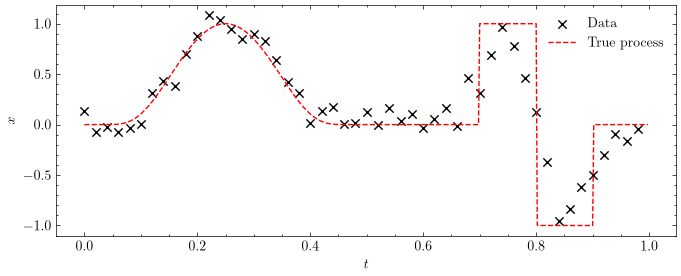

In [4]:
n_data = 50
n_true = 500
theta_true = 0.05
sigma_true = 0.1


def signal_true(x):
    term_1 = (x > 0) * (x < .5) * np.exp(4 - 25 / (10*x * (5 - 10*x)))
    term_2 = (x >= .7) * (x <= .8) * np.ones_like(x)
    term_3 = (x > .8) * (x <= .9) * (-np.ones_like(x))
    return term_1 + term_2 + term_3


def boxcar_kernel(t1, t2, theta):
    n, m = map(len, (t1, t2))
    dt = (t1[1] - t1[0]).item()
    c = dt / (2 * theta) if theta > 0 else 1.0
    k = sp.lil_array((m, n))
    for i, j in product(range(m), range(n)):
        d = abs(t2[i] - t1[j])
        d_periodic = min(d, 1.0 - d)
        if d_periodic <= theta: k[i, j] = c
    # normalize each row to preserve k@1 = (1,1,...,1)
    k /= k.sum(axis=1)[:, None]
    return k.tocsc()


t_true = np.linspace(0, 1, n_true, endpoint=False)
t_data = np.linspace(0, 1, n_data, endpoint=False)

K_true = boxcar_kernel(t_true, t_data, theta_true)
operator_true = lambda x: K_true @ x

np.random.seed(24)
x_true = signal_true(t_true)
y_data  = operator_true(x_true) + sigma_true * np.random.randn(*t_data.shape)

# plot
_, ax = plt.subplots(figsize=(8, 3))
ax.set_xlabel("$t$")
ax.set_ylabel("$x$")

ax.scatter(t_data, y_data, c="k", marker="x", label="Data")
ax.plot(t_true, x_true, 'r--', label="True process")
ax.legend()

plt.savefig("data_and_true_1.pdf")
plt.show()

### Estimating $x$ and $\theta$

Now $x$ assumed to be a Gaussian process of Matérn class, also periodic, with hyperparameters $\nu=1.5$, $\ell=0.05$, $\tau=1.0$. Moreover, let $\theta \sim \mathcal{U}[0, 1]$.

#### Using L-BFGS

Using loss function derived from negative log-posterior taking only terms dependent on $\bm{x}$ or $\theta$:
$$
-\log p(\bm{x}, \theta | y) \propto \frac{1}{2}(\bm{y} - \bm{K}_\theta \bm{x})^\intercal \bm{\Sigma}^{-1}(\bm{y} - \bm{K}_\theta \bm{x}) + \frac{1}{2} \bm{x}^\intercal \bm{C} \bm{x} + \text{constant}
$$
where now $\bm{\Sigma} = \sigma^2 \bm{I}$, and $\bm{C}$ is Matérn covariance.

In [231]:
sampler = MaternFDMSPDESampler(((0, 1),), (n_true,), (True,), nu=1.5, ell=0.05, sigma=1.0)

i = 0
def fun(param, sampler=sampler, t_true=t_true,
        t_data=t_data, y_data=y_data, sigma_true=sigma_true):
    global i
    x, theta = param[:-1], param[-1]
    K = boxcar_kernel(t_true, t_data, theta)
    neg_log_likelihood = np.sum((y_data - K @ x)**2) / sigma_true**2
    # assuming alpha=2
    quad = np.sum((sampler.tau * sampler.vol_sqrt * sampler.A @ x)**2)
    objective = neg_log_likelihood + quad
    if i % 1000 == 0:
        print(f"Iteration {i}: theta = {theta:.4f}, objective = {objective:.4f}")
    i += 1
    return objective


x0 = np.zeros(n_true + 1)
x0[-1] = 0.05
bounds = [(-2, 2)]*n_true + [(0, 1.0)]

result = sci.optimize.minimize(fun, x0=x0, method="L-BFGS-B", bounds=bounds)

Iteration 0: theta = 0.0500, objective = 1296.2200
Iteration 1000: theta = 0.0500, objective = 32677.3863
Iteration 2000: theta = 0.0500, objective = 1295.0635
Iteration 3000: theta = 0.0500, objective = 994.7484
Iteration 4000: theta = 0.0500, objective = 993.2839
Iteration 5000: theta = 0.0500, objective = 575.3141
Iteration 6000: theta = 0.0500, objective = 498.6022
Iteration 7000: theta = 0.0500, objective = 472.4159
Iteration 8000: theta = 0.0500, objective = 453.6789
Iteration 9000: theta = 0.0500, objective = 432.9344
Iteration 10000: theta = 0.0500, objective = 407.1724
Iteration 11000: theta = 0.0500, objective = 378.2909
Iteration 12000: theta = 0.0500, objective = 351.0745
Iteration 13000: theta = 0.0500, objective = 316.6826
Iteration 14000: theta = 0.0500, objective = 275.2625
Iteration 15000: theta = 0.0500, objective = 232.0762


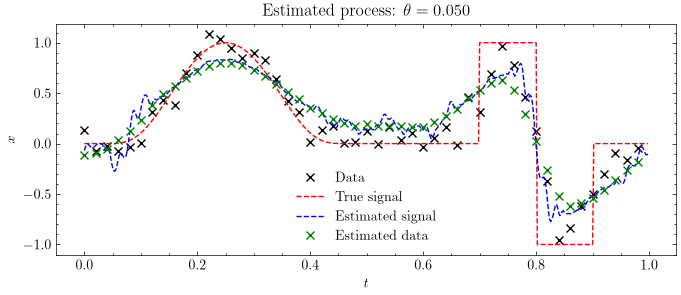

In [234]:
x_pred = result.x[:-1, None]
theta_pred = result.x[-1]
K_pred = boxcar_kernel(t_true, t_data, theta_pred)

# plot
_, ax = plt.subplots(figsize=(8, 3))
ax.set_xlabel("$t$")
ax.set_ylabel("$x$")

ax.plot(t_data, y_data, 'kx', label="Data")
ax.plot(t_true, x_true, 'r--', label="True signal")
ax.plot(t_true, x_pred, 'b--', label="Estimated signal")
ax.plot(t_data, K_pred @ x_pred, 'gx', label="Estimated data")
ax.set_title(f"Estimated process: $\\theta = {theta_pred:.3f}$")
ax.legend()

plt.savefig("estimated_process_l-bfgs_1.pdf")
plt.show()

#### Deriving $p(\bm{x} | \theta, \bm{y})$

With $\theta$ fixed, collect terms (likelihood and prior) from posterior that contribute in $\bm{x}$:
$$
\begin{aligned}
-\log p(\bm{x} | \theta, \bm{y}) &\propto \frac{1}{2}(\bm{y} - \bm{K}_\theta \bm{x})^\intercal \bm{\Sigma}^{-1}(\bm{y} - \bm{K}_\theta \bm{x}) + \frac{1}{2} \bm{x}^\intercal \bm{C}^{-1} \bm{x} + \text{constant} \\
&= \underbrace{\frac{1}{2}\bm{y}^\intercal \bm{\Sigma}^{-1} \bm{y}}_{\text{also constant}} - \bm{y}^\intercal \bm{\Sigma}^{-1} \bm{K}_\theta \bm{x} + \frac{1}{2} \bm{x}^\intercal \bm{K}_\theta^\intercal \bm{\Sigma}^{-1} \bm{K}_\theta \bm{x} + \frac{1}{2}\bm{x}^\intercal \bm{C}^{-1} \bm{x} + \text{constant} \\
&= \frac{1}{2} \bm{x}^\intercal\underbrace{\left(\bm{C}^{-1} + \bm{K}_\theta^\intercal \bm{\Sigma}^{-1} \bm{K}_\theta\right)}_{\bm{\Lambda}_\theta} \bm{x} - \bm{y}^\intercal \bm{\Sigma}^{-1}\bm{K}_\theta \bm{x} + \text{constant}
\end{aligned}
$$
Completing the square to form $(\bm{x}-\bm{M}\bm{y})^\intercal\bm{\Lambda}_\theta(\bm{x} - \bm{M}\bm{y})$ gives $\bm{M} = \bm{\Lambda}_\theta^{-1} \bm{K}_\theta^\intercal \bm{\Sigma}^{-1}$, therefore
$$
\begin{aligned}
-\log p(\bm{x} | \theta, \bm{y}) &\propto \frac{1}{2}(\bm{x} - \bm{\Lambda}_\theta^{-1} \bm{K}_\theta^\intercal \bm{\Sigma}^{-1}\bm{y})^\intercal\bm{\Lambda}_\theta(\bm{x} - \bm{\Lambda}_\theta^{-1} \bm{K}_\theta^\intercal \bm{\Sigma}^{-1}\bm{y}) + \text{constant} \\
\Leftrightarrow p(\bm{x} | \theta, \bm{y}) &= \mathcal{N}(\bm{\Lambda}_\theta^{-1} \bm{K}_\theta^\intercal \bm{\Sigma}^{-1}\bm{y}, \bm{\Lambda}_\theta^{-1})
\end{aligned}
$$

##### Taking the defined noise and SPDE approximation into account

Now, we have $\bm{\Sigma} = \sigma^2 \bm{I}$. Moreover, recall, that Matérn process using SPDE approximation yields
$$
\begin{aligned}
\bm{x} &\sim \mathcal{N}(\bm{0}, \bm{Q}^{-1}), & \bm{Q} &= \delta\tau^2 \bm{A}^\alpha, & \bm{A} = \kappa^2 \bm{I} - \bm{L},
\end{aligned}
$$
where $\alpha = \nu + \frac{d}{2}, ~ d = \dim(t)$, $\kappa = \frac{\sqrt{2\nu}}{\ell}$, $\delta = \prod_{i=1}^d \frac{1}{h_i}$ and
$$
\tau^2 = \frac{\Gamma(\nu)}{\Gamma(\alpha)(4\pi)^\frac{d}{4}\kappa^{2\nu}\sigma^2}.
$$
Now we have
$$
\bm{\Lambda}_\theta = \bm{Q} + \frac{1}{\sigma^2}\bm{K}_\theta^\intercal \bm{K}_\theta.
$$
Also, since $\nu=1.5$, i.e., $\alpha=2$, we get
$$
\begin{aligned}
-\log p(\bm{x} | \theta, \bm{y}) &= \frac{1}{2} \bm{x}^\intercal(\bm{Q} + \frac{1}{\sigma^2}\bm{K}_\theta^\intercal \bm{K}_\theta) \bm{x} - \frac{1}{\sigma^2}\bm{y}^\intercal \bm{K}_\theta \bm{x} + \text{constant} \\
&= \frac{1}{2} \Vert \sqrt{\delta}\tau\bm{A} \bm{x} \Vert^2 + \frac{1}{2\sigma^2}\Vert \bm{y} - \bm{K}_\theta \bm{x} \Vert^2 + \text{constant}, & (\sqrt{\delta}\tau\bm{A})^\intercal(\sqrt{\delta}\tau\bm{A}) = \delta\tau^2 \bm{A}^2 = \bm{Q} \\
&= \frac{1}{2} \left\Vert \begin{pmatrix}\bm{0}\\\sigma^{-1}\bm{y}\end{pmatrix} - \begin{pmatrix}\sqrt{\delta}\tau\bm{A}\\\sigma^{-1}\bm{K}_\theta\end{pmatrix}\bm{x} \right\Vert^2 + \text{constant}
\end{aligned}
$$

#### Deriving $p(\bm{x} | \theta, \bm{y})$

Similarily, taking terms contributing in $\theta$ in posterior, when $\bm{x}$ is fixed, results in:
$$
\begin{aligned}
p(\theta | \bm{x}, \bm{y}) &= \frac{1}{\sqrt{(2\pi)^n}\vert\bm{\Sigma}\vert}\exp\left(-\frac{1}{2}(\bm{y} - \bm{K}_\theta \bm{x})^\intercal \bm{\Sigma}^{-1}(\bm{y} - \bm{K}_\theta \bm{x}) \right) \bm{1}_{[0, 1]}(\theta)
\end{aligned}
$$

#### Sample $\bm{x}$ using Gibbs and $\theta$ using Metropolis–Hastings.

For $k=1,...,N_\text{chain}$
* Gibbs: solve $\bm{x}^{(k)} = \begin{pmatrix}\sqrt{\delta}\tau\bm{A}\\\sigma^{-1}\bm{K}_\theta\end{pmatrix}^\dagger \left(\begin{pmatrix}\bm{0}\\\sigma^{-1}\bm{y}\end{pmatrix} + \bm{\xi}^{(k)}\right), ~ \bm{\xi}^{(k)}\sim\mathcal{N}(\bm{0}, \bm{I})$
* MH: accept $\theta^{(k)} \sim \mathcal{N}(\theta^{(k-1)}, \beta^2)$ with probability $\min \left\{1, \frac{p(\theta^{(k)} | \bm{x}^{(k)}, \bm{y})}{p(\theta^{(k-1)} | \bm{x}^{(k)}, \bm{y})}\right\}$

In [90]:
def sample_x_theta_gibbs_mh(t, t_data, y_data, init_theta, beta_theta, sampler, log_post, sigma_noise, chain_length=10000):
    """
    t: state grid
    t_data: data grid
    y_data: data
    sampler: MaternFDMSPDESampler instance
    init_theta: boxcar window width for the kernel
    beta_theta: random walk step size in theta sampling
    log_post: log-posterior function for the mh proposal
    chain_length: length of the chain
    """

    chain_state = [np.zeros(len(t))]  # Initialize with zeros
    chain_param = []

    # old samples
    theta_old = init_theta
    K_old = boxcar_kernel(t, t_data, theta_old)
    rhs_old = sp.vstack([sampler.vol_sqrt * sampler.tau * sampler.A, sigma_noise**-1 * K_old])
    lp_old = None

    # initialize new samples
    theta_new = None
    K_new = None
    rhs_new = None
    lp_new = None

    # Misc
    lhs = np.concatenate([np.zeros((len(t),)), sigma_noise**-1 * y_data])

    for _ in tqdm(range(chain_length)):

        # sample state
        state = sp.linalg.lsqr(rhs_old, lhs + np.random.randn(*lhs.shape), x0=chain_state[-1])[0]
        lp_old = log_post(y_data, state, K_old, theta_old, sigma_noise)

        # sample param
        theta_new = theta_old + beta_theta * np.random.randn()
        K_new = boxcar_kernel(t, t_data, theta_new)
        rhs_new = sp.vstack([sampler.vol_sqrt * sampler.tau * sampler.A, sigma_noise**-1 * K_new])
        lp_new = log_post(y_data, state, K_new, theta_new, sigma_noise)
        if np.log(np.random.rand()) <= min(lp_new - lp_old, 0):
            theta_old = theta_new
            K_old = K_new
            rhs_old = rhs_new

        # add to chain
        chain_state.append(state)
        chain_param.append(theta_old)

    return tuple(map(np.asarray, (chain_state[1:], chain_param)))


def acf(chain, max_lag=100):
    chain = chain - chain.mean()
    n = len(chain)
    c = np.dot(chain, chain)
    acf_vals = [np.dot(chain[:n-k], chain[k:]) / c 
                for k in range(0, max_lag+1)]
    return np.array(acf_vals)


def ess(chain, max_lag=500):
    r = acf(chain, max_lag)
    # Find first negative lag
    cutoff = next((i for i in range(1, len(r)) if r[i] < 0), len(r))
    return len(chain) / (1 + 2 * r[1:cutoff].sum())


def plot_results(t_true, y_true, t_data, y_data,
                 chain_state, chain_theta,
                 burn_size, thinning=1, max_lags=100, bins=100):

    fig, axes = plt.subplot_mosaic(
        [[0, 1],
         [2, 3]],
        figsize=(8, 6)
    )

    state_cut = chain_state[burn_size:]
    theta_cut = chain_theta[burn_size:]

    state_thinned = state_cut[::thinning]
    theta_thinned = theta_cut[::thinning]

    mu_state = state_thinned.mean(0)
    std_state = state_thinned.std(0)
    mu_theta = theta_thinned.mean(0)
    K = boxcar_kernel(t_true, t_data, mu_theta)
    RMSE = np.sqrt(np.mean((mu_state - y_true.ravel())**2))

    axes[0].set_title(f"{RMSE = :.3f}")
    axes[0].set_xlabel("$t$")
    axes[0].set_ylabel("$x$")
    axes[0].plot(t_true, y_true, 'r--', label="True process")
    axes[0].plot(t_true, mu_state, 'b--', label="Estimated process")
    axes[0].fill_between(t_true.ravel(), mu_state - 1.96*std_state,
                          mu_state + 1.96*std_state, alpha=0.5,
                          color='gray', edgecolor=None,
                          label="Credible interval (95%)")
    axes[0].legend()

    # theta chain
    axes[1].set_xlabel(r"\# sample")
    axes[1].set_ylabel(r"$\theta$")
    axes[1].plot(chain_theta, label=r"$\theta$ chain")
    axes[1].set_title(r"Full trace of $\theta$ samples")
    axes[1].legend()

    # theta hists
    axes[2].set_xlabel(r"$\theta$")
    axes[2].set_ylabel("probability density")
    axes[2].hist(theta_thinned, bins=bins, density=True,
                 stacked=True, label=r"$\mathbb{E}[\theta] = %.3f$" % mu_theta)
    axes[2].set_title(r"Histogram of $\theta$ samples")
    axes[2].legend()


    # theta autocorr
    acorr = acf(theta_cut, max_lag=max_lags)
    ESS = ess(theta_cut, max_lag=max_lags)
    axes[3].set_xlabel(r"lag")
    axes[3].set_ylabel("autocorrelation")
    axes[3].fill_between(range(len(acorr)), acorr)
    axes[3].set_xlim(0, max_lags)
    axes[3].set_title(r"Autocorrelation of $\theta$ samples, ESS = %.1f" % ESS)

    return fig, axes

In [236]:
# theta params
init_theta = 0.0
beta_theta = 0.01

# log-posterior
def log_posterior(y_data, state, K, theta, sigma_noise):
    quad = -0.5 * (np.sum((y_data - K @ state)**2) / sigma_noise**2)
    return quad if 0 <= theta <= 1 else -np.inf

# sample
sampler = MaternFDMSPDESampler(((0, 1),), (n_true,), (True,), nu=1.5, ell=0.05, sigma=1.0)
chain_length = 10_000
chain_state, chain_param = sample_x_theta_gibbs_mh(
    t_true, t_data, y_data, init_theta, beta_theta,
    sampler, log_posterior, sigma_true, chain_length
)


  0%|          | 0/10000 [00:00<?, ?it/s]

/Users/z068427/Git/bcpe/.venv/lib/python3.12/site-packages/scipy/sparse/_base.py:1057: RuntimeWarning: divide by zero encountered in divide
  return self.multiply(np.divide(1, other))
100%|██████████| 10000/10000 [02:30<00:00, 66.31it/s]


/var/folders/r7/lrp1vtg90zx0m34pgg8fr_bs0yg2r7/T/ipykernel_99787/3544587162.py:127: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[3].legend()


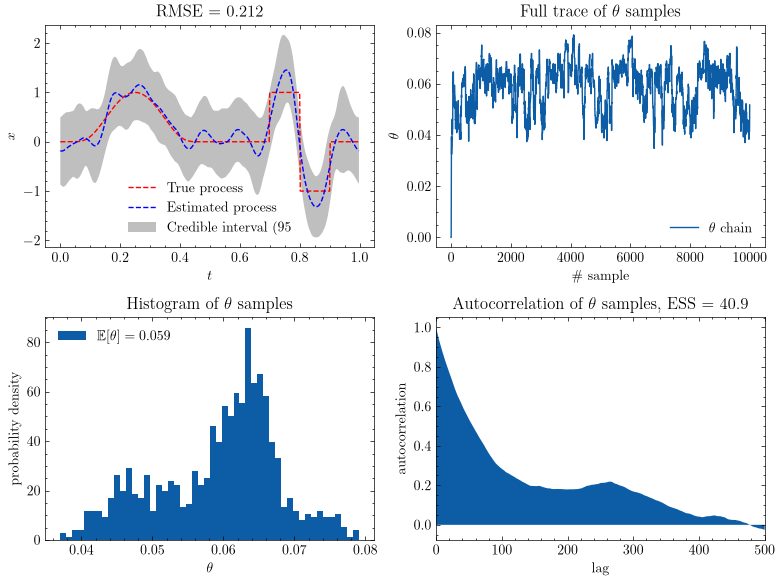

In [249]:
fig, axes = plot_results(t_true, x_true, t_data, y_data, 
                         chain_state, chain_param, burn_size=1000,
                         thinning=10, max_lags=500, bins=50)

plt.tight_layout()
fig.savefig("gibbs_mh_1.pdf")

## Kernel learning

Let $x: [0, 1] \rightarrow \mathbb{R}$ be periodic s.t. $x(t+1) = x(t)$, same with the kernel $K$. Data is generated as
* $\bm{x}_i \sim \text{matérn with } (\nu, \ell, \tau) = (1.5, 0.05, 1.0), ~ i=1,...,m$
* $\bm{y}_i = \bm{K}_{0.05} \bm{x}_i + \bm{\epsilon}_i, ~ \bm{\epsilon}_i \sim \mathcal{N}(\bm{0}, \sigma^2\bm{I}), ~ i = 1,...,m$
* $\sigma = 0.1$
* $\dim(\bm{x}_i) = \dim(\bm{k}) = 200$
* $\dim(\bm{y}_i) = 50$
* $m=20$ 

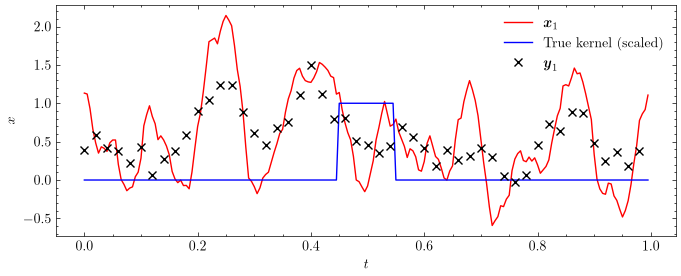

In [58]:
n_true = 200
n_data = 50
m = 20
sigma_true = 0.1
theta_true = 0.05
x_sampler = MaternFDMSPDESampler(((0, 1),), (n_true,), (True,), nu=1.5, ell=0.05, sigma=1.0)

t_true = np.linspace(0, 1, n_true, endpoint=False)
t_data = np.linspace(0, 1, n_data, endpoint=False)

np.random.seed(42)
X_data = x_sampler(n_samples=m)
K_true = boxcar_kernel(t_true, t_data, theta_true)
k_true = K_true[0].toarray()
Y_data = X_data @ K_true.T + sigma_true * np.random.randn(m, n_data)

# plot
_, ax = plt.subplots(figsize=(8, 3))
ax.set_xlabel("$t$")
ax.set_ylabel("$x$")

ax.plot(t_true, X_data[0], 'r', label=r"$\boldsymbol{x}_1$")
ax.plot(t_true, K_true[n_data//2].toarray() / theta_true, 'b', label=r"True kernel (scaled)")
ax.plot(t_data, Y_data[0], 'kx', label=r"$\boldsymbol{y}_1$")
ax.legend()

plt.savefig("data_and_true_2.pdf")
plt.show()


Now the boxcar structure is estimated as Matérn process with $(\nu, \ell, \tau) = (1.5, 0.05, 0.1)$. Since the discrete Kernel can be derived as a Toeplitz matrix
$$
\bm{K}_{\bm{k}} =
\begin{pmatrix}
k_1 & k_2 & \dots & k_n \\
k_n & k_1 & \dots & \vdots \\
\vdots & \vdots & \ddots & \vdots \\
k_2 & \dots & k_n & k_1
\end{pmatrix},
$$
the operation is linear on $\bm{k}$, i.e., for each $i=1,...,m$, there is $\bm{H}_i$, s.t.
$$
\bm{K}_{\bm{K}} \bm{x}_i = \bm{H}_i \bm{k},
$$
which is
$$
\bm{H}_i =
\begin{pmatrix}
x_i^{(1)} & x_i^{(2)} & \dots & x_i^{(n)} \\
x_i^{(2)} & x_i^{(3)} & \dots & x_i^{(1)} \\
\vdots & \vdots & \ddots & \vdots \\
x_i^{(n)} & \dots & x_i^{(2)} & x_i^{(1)}
\end{pmatrix},
$$
Toeplitz w.r.t. its anti diagonal.

In [59]:
k_sampler = MaternFDMSPDESampler(((0, 1),), (n_true,), (True,), nu=1.5, ell=0.05, sigma=0.1)

def toeplitz_reverse(t1, t2, x):
    shifts, _ = np.where(t1[:, None] == t2)
    assert len(shifts) == len(t_data)
    H = np.asarray([
        np.roll(x, -shift) for shift in shifts
    ])
    return sp.csc_array(H)

kernels = [toeplitz_reverse(t_true, t_data, x) for x in X_data]

### Estimating $K$

#### Using L-BFGS

Involving the prior, loss function is derived from negative log-posterior taking only terms dependent on $\bm{k}$:
$$
\begin{aligned}
-\log p(\bm{k} | \left\{(\bm{x}_i, \bm{y}_i)\right\}_{i=1,...,m}) &\propto \frac{1}{2} \sum_{i=1}^m (\bm{y}_i - \bm{K}_{\bm{k}} \bm{x}_i)^\intercal \bm{\Sigma}^{-1}(\bm{y}_i - \bm{K}_{\bm{k}} \bm{x}_i) + \frac{1}{2} \bm{k}^\intercal \bm{C}^{-1}_{\bm{k}} \bm{k} + \text{constant} \\
&= \frac{1}{2} \sum_{i=1}^m (\bm{y}_i - \bm{H}_i\bm{k})^\intercal \bm{\Sigma}^{-1}(\bm{y}_i - \bm{H}_i \bm{k}) + \frac{1}{2} \bm{k}^\intercal \bm{C}_{\bm{k}}^{-1} \bm{k} + \text{constant} \\
\end{aligned}
$$
where $\bm{\Sigma} = \sigma^2 \bm{I}$, and $\bm{C}_{\bm{k}}$ is Matérn covariance of $\bm{k}$.

In [73]:
i = 0
def fun(k, sampler=k_sampler, Y_data=Y_data, sigma=sigma_true):
    global i
    neg_log_likelihood = np.sum(
        [(Y_data[i] - kernels[i] @ k)**2 for i in range(len(kernels))]
    )
    # assuming alpha=2
    quad = np.sum((sampler.vol_sqrt * sampler.tau * sampler.A @ k)**2)
    objective = neg_log_likelihood + quad
    if i % 1000 == 0:
        print(f"Iteration {i}: objective = {objective:.4f}")
    i += 1
    return objective

x0 = np.zeros(n_true)
bounds = [(-0.1, 0.1)]*n_true

result = sci.optimize.minimize(fun, x0=x0, method="L-BFGS-B", bounds=bounds)

Iteration 0: objective = 726.5440
Iteration 1000: objective = 123.3961
Iteration 2000: objective = 14.5149
Iteration 3000: objective = 12.4291
Iteration 4000: objective = 11.9341
Iteration 5000: objective = 11.8644
Iteration 6000: objective = 11.8427
Iteration 7000: objective = 11.8400
Iteration 8000: objective = 11.8391
Iteration 9000: objective = 11.8390
Iteration 10000: objective = 11.8389
Iteration 11000: objective = 11.8389
Iteration 12000: objective = 11.8389
Iteration 13000: objective = 11.8389


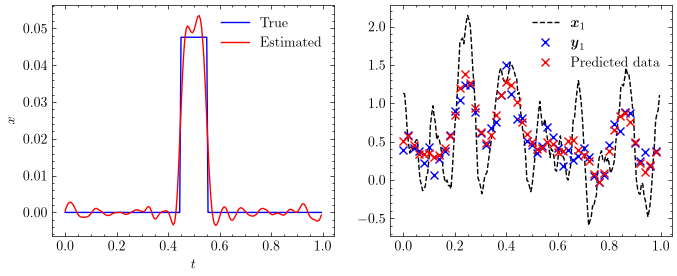

In [74]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3))
ax1.set_xlabel("$t$")
ax1.set_ylabel("$x$")

ax1.plot(t_true, np.roll(k_true, n_true // 2), 'b', label="True")
ax1.plot(t_true, np.roll(result.x, n_true // 2), 'r', label="Estimated")
ax1.legend()

ax2.plot(t_true, X_data[0], 'k--', label=r"$\boldsymbol{x}_1$")
ax2.plot(t_data, Y_data[0], 'bx', label=r"$\boldsymbol{y}_1$")
ax2.plot(t_data, kernels[0] @ result.x, 'rx', label="Predicted data")
ax2.legend()

fig.savefig("l-bfgs_2.pdf")

#### Deriving $p(\bm{k} | \left\{(\bm{x}_i, \bm{y}_i)\right\}_{i=1,...,m})$

$$
\begin{aligned}
-\log p(\bm{k} | \left\{(\bm{x}_i, \bm{y}_i)\right\}_{i=1,...,m}) &= \frac{1}{2} \sum_{i=1}^m \left[ (\bm{y}_i - \bm{H}_i\bm{k})^\intercal \bm{\Sigma}^{-1}(\bm{y}_i - \bm{H}_i \bm{k}) + \frac{1}{m} \bm{k}^\intercal \bm{C}_{\bm{k}}^{-1} \bm{k} \right] + \text{constant} \\
&= \frac{1}{2} \sum_{i=1}^m \left[ \bm{k}^\intercal \underbrace{ \left(\frac{1}{m}\bm{C}_{\bm{k}}^{-1} + \bm{H}_i^\intercal \bm{\Sigma}^{-1} \bm{H}_i \right)}_{\bm{\Lambda}_i} \bm{k} - 2\bm{y}_i^\intercal \bm{\Sigma}^{-1} \bm{H}_i \bm{k} \right] + \text{constant} \\
\end{aligned}
$$
Completing the square of form $(\bm{k}-\bm{M}_i\bm{y})^\intercal\bm{\Lambda}_i(\bm{k} - \bm{M}_i\bm{y})$ gives $\bm{M}_i = \bm{\Lambda}_i^{-1} \bm{H}_i^\intercal \bm{\Sigma}^{-1}$, therefore
$$
\begin{aligned}
-\log p(\bm{k} | \left\{(\bm{x}_i, \bm{y}_i)\right\}_{i=1,...,m}) &\propto \frac{1}{2} \sum_{i=1}^m (\bm{k} - \bm{\Lambda}_i^{-1} \bm{H}_i^\intercal \bm{\Sigma}^{-1}\bm{y})^\intercal\bm{\Lambda}_i(\bm{k} - \bm{\Lambda}_i^{-1} \bm{H}_i^\intercal \bm{\Sigma}^{-1}\bm{y}) + \text{constant} \\
\Leftrightarrow p(\bm{k} | \left\{(\bm{x}_i, \bm{y}_i)\right\}_{i=1,...,m}) &= \prod_{i=1}^{m}\mathcal{N}(\bm{\Lambda}_i^{-1} \bm{H}_i^\intercal \bm{\Sigma}^{-1}\bm{y}, \bm{\Lambda}_i^{-1})
\end{aligned}
$$
Doing all the same white noise / SPDE approximation shenanigans gives us $\bm{\Lambda}_i =  \frac{1}{m}\bm{Q}_{\bm{k}} + \frac{1}{\sigma^2}\bm{H}_i^\intercal \bm{H}_i$, and
$$
\begin{aligned}
-\log p(\bm{k} | \left\{(\bm{x}_i, \bm{y}_i)\right\}_{i=1,...,m}) &= \frac{1}{2} \sum_{i=1}^m \left[ \bm{k}^\intercal \left(\frac{1}{m}\bm{Q}_{\bm{k}} + \frac{1}{\sigma^2}\bm{H}_i^\intercal \bm{H}_i \right) \bm{k} - \frac{2}{\sigma^2}\bm{y}_i^\intercal \bm{H}_i \bm{k} \right] + \text{constant} \\
&= \frac{1}{2} \Vert \sqrt{\delta}\tau \bm{A} \bm{k} \Vert^2 + \frac{1}{2} \sum_{i=1}^m \frac{1}{\sigma^2} \Vert \bm{y}_i - \bm{H}_i \bm{k} \Vert^2 + \text{constant} \\
&= \frac{1}{2} \left\Vert
\begin{pmatrix}
\bm{0}\\\sigma^{-1}\bm{y}_1\\\vdots\\\sigma^{-1}\bm{y}_m
\end{pmatrix} -
\begin{pmatrix}
\sqrt{\delta}\tau \bm{A}\\\sigma^{-1}\bm{H}_1\\\vdots\\\sigma^{-1}\bm{H}_m\\
\end{pmatrix} \bm{k}
\right\Vert^2 + \text{constant}
\end{aligned}
$$

#### Sampling time

Gibbs sampler now repeats
$$
\bm{x}^{k} = \begin{pmatrix}
\sqrt{\delta}\tau \bm{A}\\\sigma^{-1}\bm{H}_1\\\vdots\\\sigma^{-1}\bm{H}_m\\
\end{pmatrix}^\dagger
\left( \begin{pmatrix}
\bm{0}\\\sigma^{-1}\bm{y}_1\\\vdots\\\sigma^{-1}\bm{y}_m
\end{pmatrix} + \bm{\xi} \right) ~ \bm{\xi} \sim \mathcal{N}(\bm{0}, \bm{I})
$$

In [92]:
def sample_gibbs(t_x, t_y, X, Y, sampler, sigma, chain_length=1000):
    """
    t_x: state grid
    t_y: data grid
    X: state set
    Y: data set
    sampler: MaternFDMSPDESampler instance
    chain_length: length of the chain
    """
    H = sp.vstack([toeplitz_reverse(t_x, t_y, x) for x in X])
    rhs = sp.vstack([
        sampler.vol_sqrt * sampler.tau * sampler.A,
        sigma**-1 * H
    ])
    lhs = np.concatenate([
        np.zeros(len(t_x)),
        sigma**-1 * np.concatenate(Y)
    ])
    chain = np.zeros((chain_length + 1, len(t_x)))
    for i in tqdm(range(chain_length)):
        xi = np.random.randn(*lhs.shape)
        chain[i+1] = sp.linalg.lsqr(rhs, lhs + xi, x0=chain[i])[0]

    return chain[1:]


def plot_gibbs(t, k, chain, burn_size, thinning=1, max_lags=100):

    fig, axes = plt.subplots(1, 2, figsize=(8, 3))

    cut = chain[burn_size:]
    thinned = cut[::thinning]

    n = len(k)
    mu = thinned.mean(0)
    std = thinned.std(0)
    lower = mu - 1.96*std
    upper = mu + 1.96*std

    axes[0].set_xlabel("$t$")
    axes[0].set_ylabel("$k$")
    axes[0].plot(t, np.roll(k, n//2), 'b', label="True kernel")
    axes[0].plot(t, np.roll(mu, n//2), 'r', label="Estimated kernel")
    axes[0].fill_between(t, np.roll(lower, n//2), np.roll(upper, n//2), alpha=0.5,
                         color='gray', edgecolor=None,
                         label="Credible interval (95%)")
    axes[0].legend()

    # autocorr
    middle = cut[:, 0]
    acorr = acf(middle, max_lag=max_lags)
    ESS = ess(middle, max_lag=max_lags)
    axes[1].set_xlabel(r"lag")
    axes[1].set_ylabel("autocorrelation")
    axes[1].fill_between(range(len(acorr)), acorr)
    axes[1].set_xlim(0, max_lags)
    axes[1].set_title(r"Autocorrelation of $k(0)$, ESS = %.1f" % ESS)

    return fig, axes

In [88]:
# sample
chain_length = 1000
chain = sample_gibbs(
    t_true, t_data, X_data, Y_data, k_sampler,
    sigma_true, chain_length
)

100%|██████████| 1000/1000 [00:09<00:00, 104.54it/s]


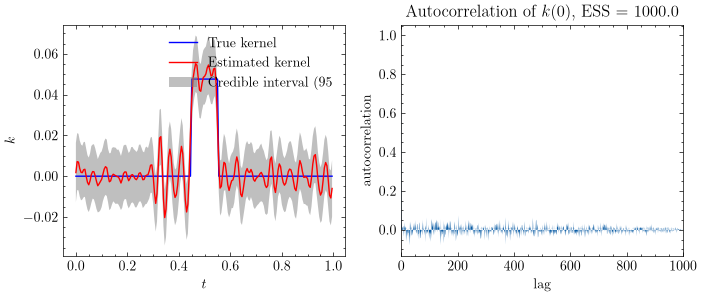

In [94]:
fig, axes = plot_gibbs(t_true, k_true, chain, 0,
                       thinning=1, max_lags=1000)
fig.savefig("gibbs_2.pdf")